# Exercice 4 — Sélection de variables

In [153]:
from sklearn.datasets import make_classification

from sklearn.feature_selection import SelectKBest , f_classif  , RFE

from sklearn.metrics import accuracy_score , f1_score

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier 

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt


### Generation du dataset

In [154]:
x, y = make_classification(

    n_samples=600 ,
    n_features=20 ,
    n_informative=5 ,
    n_redundant=5 ,
    n_repeated=0 ,
    n_classes=2 ,
    random_state=0

)


### Nomme les colonnes feature_1 à feature_20

In [155]:
col_name = [f"feature_{i}" for i in range(1,21)]

x = pd.DataFrame(x , columns=col_name)

x

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20
0,0.049110,0.739306,1.681256,-1.462401,-0.912801,-1.315979,-1.331710,0.028945,0.358152,2.010762,0.190004,-0.793215,0.448422,0.714318,1.441232,-0.290300,-0.533449,-0.419997,-1.423013,0.409161
1,1.107646,-1.599808,1.847242,0.616600,1.012930,0.597431,0.948818,-0.484914,0.326829,1.444061,-0.726294,2.399032,0.015320,1.122734,-0.875814,1.152184,0.517990,-1.110928,0.445087,2.950145
2,-1.997663,-0.248135,-0.029909,0.795361,1.350912,-0.040838,0.509641,0.816314,0.748407,-0.076420,-0.321188,-1.207441,0.958877,0.456749,0.329065,-1.496360,0.578980,-1.068739,-0.101554,1.258244
3,0.454945,-0.687466,-0.750209,-0.295884,-0.161230,-0.697374,-0.205357,0.651706,0.329064,-0.171571,2.203328,0.313551,0.436543,1.333510,1.394645,-0.886081,1.484610,0.925474,-0.813899,-1.176149
4,-1.920142,-2.333417,2.433427,0.021410,0.611465,0.912927,-1.189500,-0.177773,-1.836781,2.156512,-0.576145,1.463860,2.950123,-0.004038,0.540477,-0.501029,0.169769,-4.211202,-1.970835,5.779847
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,-1.005835,1.894735,1.690706,1.326330,0.504667,1.011766,0.329812,-1.777995,-1.743574,-0.027002,-1.273357,-0.729320,-1.720126,0.941182,-1.067046,0.698024,1.925873,-2.100102,-0.872118,2.888516
596,0.247927,-1.281990,0.535942,-0.219239,-0.256902,0.687571,0.573581,-1.012439,0.251553,0.222792,-1.104717,2.050350,0.897053,-0.957773,0.330972,-0.427856,1.077630,-1.652957,0.452191,2.105267
597,-1.221774,1.375351,1.604779,1.451478,0.489961,-0.947944,0.173123,-1.648670,-1.105994,-0.063200,0.492369,-0.432456,-1.280589,0.656145,0.092787,-1.402556,-1.244000,-2.405339,0.032762,3.316081
598,1.912189,-1.384876,1.916227,-1.194213,0.149528,-0.473427,0.924064,-1.795273,1.109262,1.605413,-0.483126,3.403693,0.543859,0.455427,0.157092,1.028563,-1.034817,-1.663285,-0.836504,2.594786


### Utilise 3 méthodes de sélection

SelectKBest

In [156]:
selector = SelectKBest(score_func=f_classif, k=5)

selector.fit_transform(x,y)

m1_best = x.columns[selector.get_support()]

m1_best = np.array(m1_best)


m1_best

array(['feature_1', 'feature_2', 'feature_4', 'feature_18', 'feature_20'],
      dtype=object)

Random forest

In [157]:
model = RandomForestClassifier(n_estimators=300, random_state=0)

model.fit(x,y)

model.score(x,y)

importance = model.feature_importances_

df =  pd.DataFrame({

        "variable" : x.columns,

        "importance" : importance
}
)

df

,variable,importance
0,feature_1,0.244858
1,feature_2,0.092766
2,feature_3,0.039180
3,feature_4,0.053072
4,feature_5,0.010597
5,feature_6,0.014932
6,feature_7,0.016335
7,feature_8,0.065732
8,feature_9,0.013983
9,feature_10,0.075907


In [158]:
df = df.sort_values("importance" ,ascending=False)

m2_best = df['variable'][0:5]

m2_best =  np.array(m2_best)

m2_best


array(['feature_1', 'feature_18', 'feature_2', 'feature_10', 'feature_8'],
      dtype=object)

RFE

In [159]:
model = LogisticRegression()

selector = RFE(

    estimator=model,

    n_features_to_select=5

)

selector.fit_transform(x,y)

m3_best = x.columns[selector.get_support()]

m3_best =  np.array(m3_best)

m3_best

array(['feature_1', 'feature_2', 'feature_10', 'feature_12', 'feature_18'],
      dtype=object)

### Liste des 5 variables sélectionnées et comparaison entre elles

In [160]:
all_best_var = np.concat([m1_best,m2_best,m3_best],axis=0)

all_best_var ,n = np.unique(all_best_var,return_index=True)

indices = np.argsort(n)

all_best_var = all_best_var[indices]

all_counts = n[indices]

all_best_var = all_best_var[0:5]

all_best_var

array(['feature_1', 'feature_2', 'feature_4', 'feature_18', 'feature_20'],
      dtype=object)

### Graphique à barres (Matplotlib) des importances données par la forêt aléatoire

<BarContainer object of 20 artists>

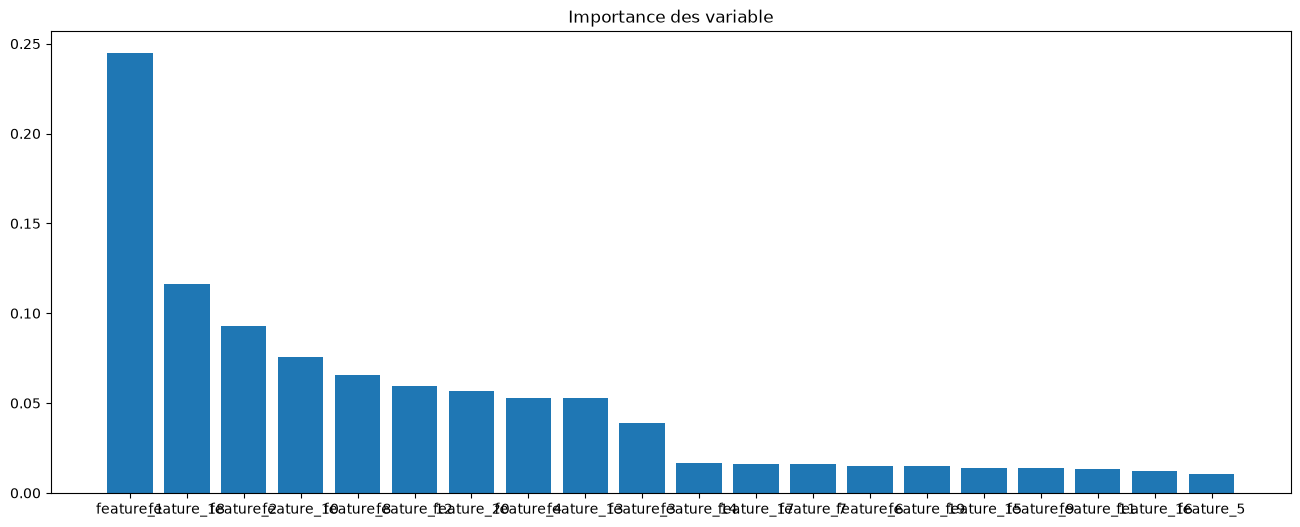

In [161]:
fig , ax =  plt.subplots(figsize=(16,6))

ax.set_title("Importance des variable")

ax.bar(df['variable'],df['importance'])

### Entraîne un LogisticRegression sur les 20 variables, puis un second uniquement sur les 5 variables

In [162]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.3)

### Model 1

In [165]:
model1 = LogisticRegression()

model1.fit(x_train,y_train)

model1.score(x_train,y_train)

model1.score(x_test,y_test)

0.8888888888888888

### Model 2

In [166]:
model2 = LogisticRegression()

model2.fit(x_train[all_best_var],y_train)

model2.score(x_train[all_best_var],y_train)

model2.score(x_test[all_best_var],y_test)

0.8833333333333333

### Comparaison des metric

accuracy

In [174]:
pred_m1 = model1.predict(x_test)

acc = accuracy_score(y_test,pred_m1)

acc

0.8888888888888888

In [176]:
pred_m2 = model2.predict(x_test[all_best_var])

acc = accuracy_score(y_test,pred_m2)

acc

0.8833333333333333

f1-score

In [177]:
acc = f1_score(y_test,pred_m1)

acc

0.8913043478260869

In [178]:
acc = f1_score(y_test,pred_m2)

acc

0.88268156424581